In [84]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigh

# Solving Hydrogen atom (with pre-defined ALPHAs)

In class was described how the Schrodinger equation, $H\psi_i(r) = \varepsilon_i\psi_i(r)$, can be casted as a general eigenvalue problem of the following type

$$\sum_j H_{ij}C^i_j = \varepsilon_i \sum_j S_{ij} C^i_j \hspace{1cm}\psi_i(r) = \sum_j C^i_j \phi_j(r).$$

Where the wavefunction $\psi_i$ was decomposed using a general set of basis function $\{\phi_j\}$ and the vector $\mathbf{C}^i$ contains its expansion coefficients under such base. In this formalism it's easy to define the Hamiltonian and Overlap matrix that define the general wigenvalue problem as

$$H_{ij} = \int \mathrm{d}r \phi_i^*(r) H\phi_j(r)\hspace{1cm} S_{ij} = \int \mathrm{d}r \phi_i(r)^*\phi_j(r).$$

In our case we are going to define the basis functions as a set of Gaussians of the form $\phi_j(r) = \exp(-\alpha_j r^2)$ which allows us to find analytical forms for the integrals defining the matrices as follows

$$H_{ij} = 3\pi^{1.5}\frac{\alpha_i\alpha_j}{(\alpha_i + \alpha_j)^{2.5}} - \frac{2\pi}{\alpha_i + \alpha_j}\hspace{1cm} S_{ij} = \left(\frac{\pi}{\alpha_i + \alpha_j}\right)^{1.5}.$$

With such form we can easily solve the eigenvalue problem numerically tring to vary the number and values of $\{\alpha_i\}$ to search for the best approximation of the ground state.

## Inputs

In [85]:
def V(r):
    return -1/r 

def gaussian_bassis(a, r):
    return np.exp(-a * r**2)

N_basis = 5
a_set = [13.007, 1.99, 0.4, 0.2, 0.1]  # Example values for a_set

r = np.linspace(0.01, 10, 1000)

def H_matrix(a_set, r):
    N = len(a_set)
    H = np.zeros((N, N))
    for i in range(N):
        for j in range(N):
            T_ij = 3 * a_set[i] * (a_set[j] * np.pi ** (3/2)) * ((1/(a_set[i] + a_set[j]))**(5/2))
            A_ij = - 2 * np.pi / (a_set[i] + a_set[j])
            H[i, j] = T_ij + A_ij
    return H

def S_matrix(a_set, r):
    N = len(a_set)
    S = np.zeros((N, N))
    for i in range(N):
        for j in range(N):
            S_ij = (np.pi/(a_set[i] + a_set[j]))**(3/2)
            S[i, j] = S_ij
    return S

In [86]:
H = H_matrix(a_set, r)
S = S_matrix(a_set, r)
E, coeffs = eigh(H, S)
print("Eigenvalues (Energies):")
for i, energy in enumerate(E):
    print(f"Eigenvalue {i + 1}: E = {energy:.10f}")

Eigenvalues (Energies):
Eigenvalue 1: E = -0.4990539789
Eigenvalue 2: E = -0.0328741151
Eigenvalue 3: E = 0.6183218329
Eigenvalue 4: E = 3.1402797931
Eigenvalue 5: E = 21.6359121013


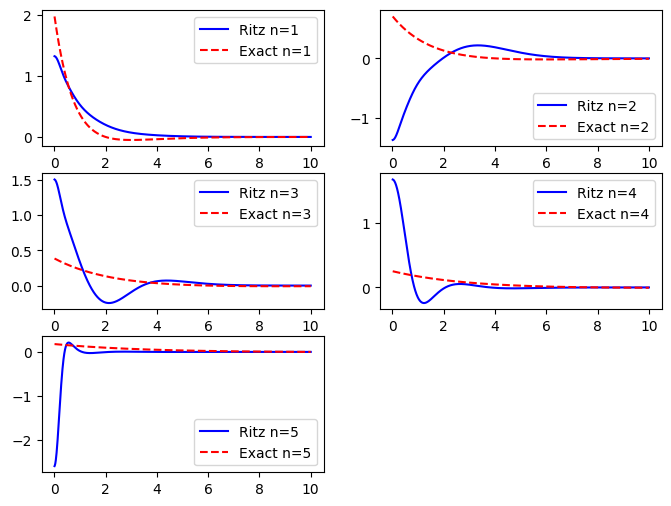

In [87]:
def psi(r, coeffs, a_set):
    psi_r = np.zeros_like(r)
    for i in range(len(a_set)):
        psi_r += coeffs[i] * gaussian_bassis(a_set[i], r)
    norm = np.trapezoid(psi_r**2, r)
    return psi_r / np.sqrt(norm)

def psi_exact(r, n):
    return (2 / n**(3/2)) * np.exp(-r / n) * (1 - r / (2 * n))

#only ground state
fig, axes = plt.subplots(3, 2, figsize=(8, 6))
for i in range(3):
    for j in range(2):
        n = i * 2 + j + 1
        if n > len(E):
            axes[i, j].axis('off')
            continue
        psi_r = psi(r, coeffs[:, n-1], a_set)
        psi_ex = psi_exact(r, n)
        axes[i, j].plot(r, psi_r, label=f'Ritz n={n}', color='blue')
        axes[i, j].plot(r, psi_ex, label=f'Exact n={n}', color='red', linestyle='dashed')
        axes[i, j].legend()
